# Контрольная работа № 2
## Комплексные числа. Геометрия комплексных чисел
Решения всех пунктов 2.1–2.10 листка № 2, включая задания со звёздочкой и оба пункта с номером 2.10.
Источник условий: «Практические занятия Листок 2.pdf», составитель П. Е. Рябов.
Выполнено по приложенному листку; он посвящён комплексным числам, хотя ранее на странице КР-2 в СДО были указаны дифференциальные уравнения. Соответствие листка заданию преподавателя следует учитывать при сдаче.
Все корни в заданиях 2.2–2.3 понимаются как множества комплексных значений. Для аргумента используется главная ветвь в интервале от минус пи (не включая) до пи (включая).
В пункте 2.4e сохранены границы неравенства из оригинала: условие противоречиво, поэтому ответом является пустое множество.
Для запуска ноутбука нужны numpy, scipy, sympy, mpmath, matplotlib. Все ячейки выполняются последовательно командой Run All. Результаты уже сохранены внутри ноутбука.

In [1]:
from pathlib import Path
import numpy as np
import sympy as sp
import mpmath as mp
import matplotlib.pyplot as plt
from scipy.special import loggamma
from IPython.display import display

mp.mp.dps = 60
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})
FIG = Path('figures')
FIG.mkdir(exist_ok=True)
def save_show(name):
    plt.savefig(FIG / name, dpi=170, bbox_inches='tight')
    plt.show()
def complex_axes(ax, title):
    ax.axhline(0, color='gray', lw=.6)
    ax.axvline(0, color='gray', lw=.6)
    ax.set_aspect('equal')
    ax.grid(alpha=.25)
    ax.set(xlabel='Re z', ylabel='Im z', title=title)

## 2.1. Три формы комплексного числа
### a)
Раскрываем скобки и умножаем числитель и знаменатель на сопряжённое к знаменателю число:
$$\frac{(5+i)(7-6i)}{3+i}=\frac{41-23i}{3+i}=\frac{(41-23i)(3-i)}{10}=10-11i.$$
Модуль и главный аргумент:
$$r=\sqrt{221},\qquad \varphi=-\arctan\frac{11}{10}.$$
Тригонометрическая и показательная формы:
$$\sqrt{221}(\cos\varphi+i\sin\varphi),\qquad \sqrt{221}e^{i\varphi}.$$
### b)
$$1+i=\sqrt{2}e^{i\pi/4},\qquad 1-i=\sqrt{2}e^{-i\pi/4}.$$
$$\frac{(1+i)^5}{(1-i)^3}=2e^{2\pi i}=2=2(\cos0+i\sin0)=2e^{0i}.$$
### c)
$$-1\pm i\sqrt{3}=2e^{\pm 2\pi i/3}.$$
После возведения в степень 15 оба числителя равны 32768. Оба знаменателя равны минус 1024:
$$(1\pm i)^{20}=2^{10}e^{\pm5\pi i}=-1024.$$
$$\frac{32768}{-1024}+\frac{32768}{-1024}=-64=64(\cos\pi+i\sin\pi)=64e^{i\pi}.$$

In [2]:
i = sp.I
answers21 = [sp.simplify((5+i)*(7-6*i)/(3+i)),
             sp.simplify((1+i)**5/(1-i)**3),
             sp.simplify(sp.expand_complex((-1+i*sp.sqrt(3))**15/(1-i)**20
                                           +(-1-i*sp.sqrt(3))**15/(1+i)**20))]
assert answers21 == [10-11*i, 2, -64]
for label, value in zip('abc', answers21):
    print(label, value, 'модуль =', sp.Abs(value), 'аргумент =', sp.N(sp.arg(value), 12))

a 10 - 11*I модуль = sqrt(221) аргумент = -0.832981266674
b 2 модуль = 2 аргумент = 0
c -64 модуль = 64 аргумент = 3.14159265359


## 2.2. Уравнение восьмой степени
$$z^8=1+i=\sqrt{2}e^{i\pi/4}.$$
Приравниваем модули и аргументы с учётом всех оборотов:
$$z_k=2^{1/16}e^{i(\pi/32+k\pi/4)},\qquad k=0,1,\ldots,7.$$
Это вершины правильного восьмиугольника с центром в нуле и радиусом примерно 1.044274. Первая вершина имеет аргумент, равный пи, делённому на 32.

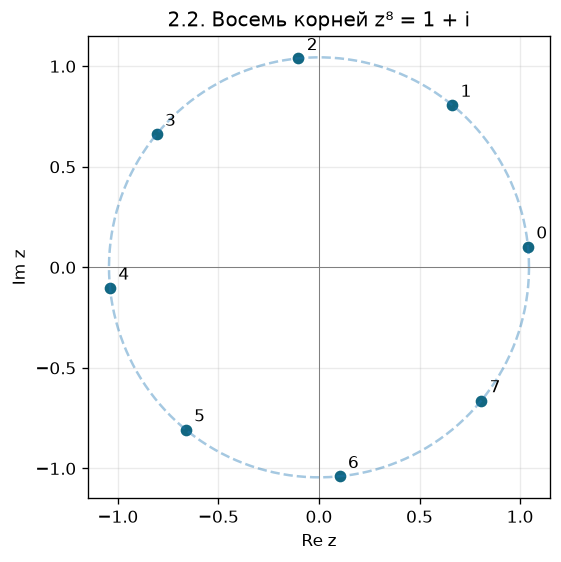

0 1.0392453187+0.1023567299i
1 0.6624802744+0.8072345500i
2 -0.1023567299+1.0392453187i
3 -0.8072345500+0.6624802744i
4 -1.0392453187-0.1023567299i
5 -0.6624802744-0.8072345500i
6 0.1023567299-1.0392453187i
7 0.8072345500-0.6624802744i


In [3]:
roots22 = 2**(1/16) * np.exp(1j*(np.pi/32 + np.arange(8)*np.pi/4))
assert np.max(abs(roots22**8-(1+1j))) < 1e-12
fig, ax = plt.subplots(figsize=(6, 5))
t = np.linspace(0, 2*np.pi, 500)
ax.plot(2**(1/16)*np.cos(t), 2**(1/16)*np.sin(t), '--', alpha=.4)
ax.scatter(roots22.real, roots22.imag, color='#126782')
for k, z in enumerate(roots22):
    ax.annotate(str(k), (z.real, z.imag), xytext=(5, 5), textcoords='offset points')
complex_axes(ax, '2.2. Восемь корней z⁸ = 1 + i')
save_show('2_2.png')
for k, z in enumerate(roots22): print(k, f'{z.real:.10f}{z.imag:+.10f}i')

## 2.3. Все значения комплексных корней
### a) Восьмые корни из единицы
$$z_k=e^{ik\pi/4},\qquad k=0,1,\ldots,7.$$
Они лежат на единичной окружности и включают 1, i, минус 1, минус i и четыре точки с координатами, равными плюс или минус корню из 2, делённому на 2.
### b) Четвёртые корни
$$-\frac{18}{1+i\sqrt{3}}=-\frac{9}{2}+i\frac{9\sqrt{3}}{2}=9e^{2\pi i/3}.$$
$$z_k=\sqrt{3}e^{i(\pi/6+k\pi/2)},\qquad k=0,1,2,3.$$
В алгебраической форме:
$$\frac{3}{2}+i\frac{\sqrt{3}}{2},\quad-\frac{\sqrt{3}}{2}+\frac{3}{2}i,\quad-\frac{3}{2}-i\frac{\sqrt{3}}{2},\quad\frac{\sqrt{3}}{2}-\frac{3}{2}i.$$
### c) Кубические корни
Весь многочлен под чертой радикала входит в подкоренное выражение:
$$\frac{1-5i}{1+i}=-2-3i,\quad\frac{1+2i}{2-i}=i,\quad(-2-3i)-5i+11=9-8i.$$
$$z_k=145^{1/6}e^{i(-\arctan(8/9)+2\pi k)/3},\qquad k=0,1,2.$$
### d) Девятые корни из 1 минус i
$$1-i=\sqrt{2} e^{-i\pi/4},\qquad z_k=2^{1/18}e^{i(-\pi/36+2\pi k/9)},\qquad k=0,\ldots,8.$$

a 0 1.0000000000+0.0000000000i
a 1 0.7071067812+0.7071067812i
a 2 0.0000000000+1.0000000000i
a 3 -0.7071067812+0.7071067812i
a 4 -1.0000000000+0.0000000000i
a 5 -0.7071067812-0.7071067812i
a 6 -0.0000000000-1.0000000000i
a 7 0.7071067812-0.7071067812i
b 0 1.5000000000+0.8660254038i
b 1 -0.8660254038+1.5000000000i
b 2 -1.5000000000-0.8660254038i
b 3 0.8660254038-1.5000000000i
c 0 2.2251634907-0.5497593220i
c 1 -0.6364762065+2.2019277715i
c 2 -1.5886872842-1.6521684495i
d 0 1.0353045309-0.0905774098i
d 1 0.8513113196+0.5960946033i
d 2 0.2689800805+1.0038473266i
d 3 -0.4392099276+0.9418887293i
d 4 -0.9418887293+0.4392099276i
d 5 -1.0038473266-0.2689800805i
d 6 -0.5960946033-0.8513113196i
d 7 0.0905774098-1.0353045309i
d 8 0.7348672461-0.7348672461i


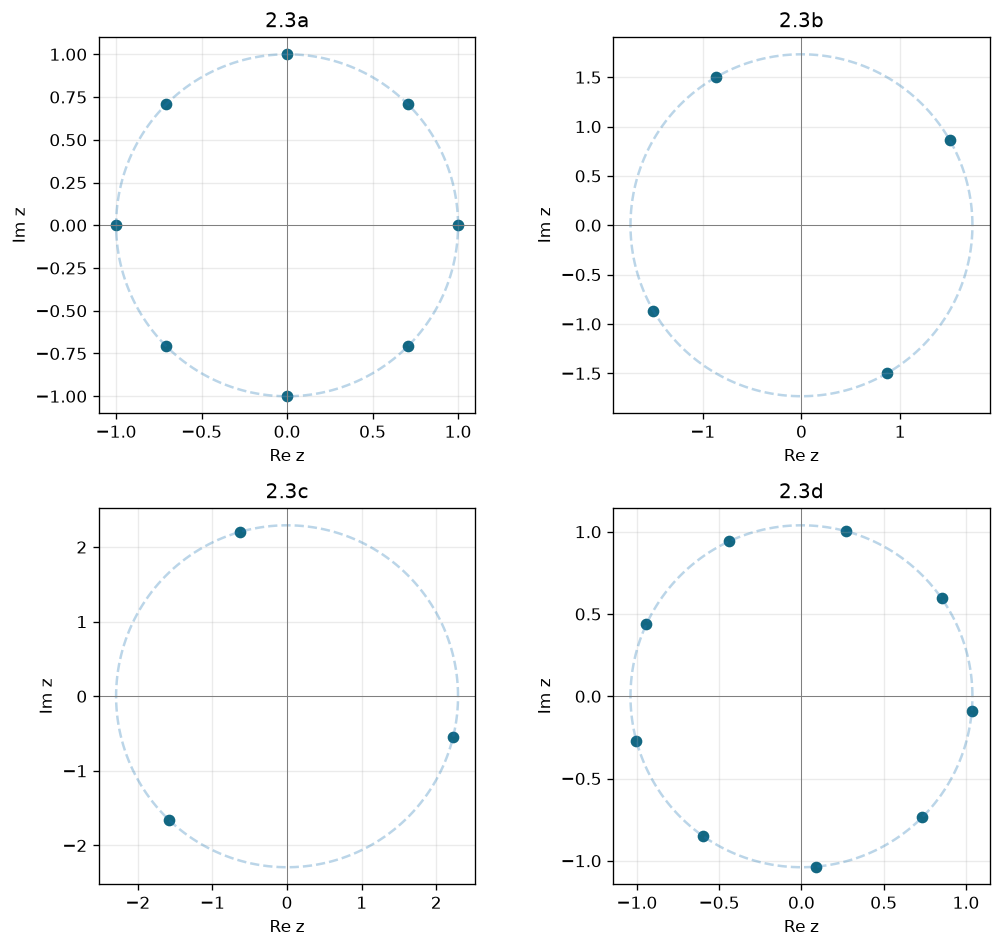

In [4]:
def all_roots(w, n):
    return abs(w)**(1/n)*np.exp(1j*(np.angle(w)+2*np.pi*np.arange(n))/n)
radicand = (1-5j)/(1+1j) - 5*(1+2j)/(2-1j) + 11
assert abs(radicand - (9-8j)) < 1e-12
root_sets = [all_roots(1,8), all_roots(-18/(1+1j*np.sqrt(3)),4),
             all_roots(radicand,3), all_roots(1-1j,9)]
fig, axes = plt.subplots(2,2,figsize=(9,8))
for ax, label, zs, w, n in zip(axes.flat, 'abcd', root_sets,
                              [1,-18/(1+1j*np.sqrt(3)),9-8j,1-1j], [8,4,3,9]):
    assert np.max(abs(zs**n-w)) < 1e-10
    ax.scatter(zs.real,zs.imag, color='#126782')
    radius = abs(zs[0]); t = np.linspace(0,2*np.pi,400)
    ax.plot(radius*np.cos(t),radius*np.sin(t),'--',alpha=.3)
    complex_axes(ax, '2.3' + label)
    for k,z in enumerate(zs): print(label,k,f'{z.real:.10f}{z.imag:+.10f}i')
plt.tight_layout()
save_show('2_3.png')

## 2.4. Геометрические множества
Положим z равным x плюс iy, где x и y действительны.
### a) Внутренность эллипса
Фокусы находятся в точках i и минус i. Сумма расстояний меньше 4, поэтому большая полуось равна 2, фокусное расстояние равно 1, малая полуось равна корню из 3:
$$\frac{x^2}{3}+\frac{y^2}{4}<1.$$
Граница не входит в множество.
### b) Открытая полуплоскость
$$\operatorname{Re}[(x+iy)(1-i)]=x+y,\qquad x+y<\sqrt{2}.$$
### c) Одна точка
Из равенства расстояний до i и минус i следует y = 0. Тогда равенство расстояний до минус 1 и i даёт:
$$(x+1)^2=x^2+1,\qquad x=0.$$
Ответ: только точка z = 0.
### d) Правая половина открытого единичного круга
В оригинале дробь имеет вид (i минус z), делённое на (z плюс i):
$$\frac{i-z}{z+i}=\frac{1-x^2-y^2+2ix}{x^2+(y+1)^2}.$$
Аргумент строго между 0 и половиной пи означает строго положительные действительную и мнимую части:
$$x>0,\qquad x^2+y^2<1.$$
### e) Пустое множество
В исходнике нижняя граница равна минус 120 градусам, а верхняя минус 150 градусам. Нижняя граница больше верхней:
$$-\frac{2\pi}{3}\leq\arg\frac{2-iz}{z+3i}\leq-\frac{5\pi}{6}.$$
Ни одно действительное значение аргумента не удовлетворяет этому двойному неравенству. Ответ: пустое множество. Перестановка границ дала бы другую задачу, поэтому в решении условие сохранено.
### f) Область между дугами окружностей
$$\frac{3-z}{z+i}=\frac{U+iV}{x^2+(y+1)^2},\quad U=3x-x^2-y^2-y,\quad V=x-3y-3.$$
Сектор аргументов от минус 120 до минус 60 градусов задаётся неравенством:
$$V\leq-\sqrt{3}|U|,\qquad z\neq-i,\quad z\neq3.$$
Граничные дуги принадлежат окружностям, задаваемым уравнениями ниже; выбираются только части, для которых V неположительно:
$$x^2+y^2-(3+1/\sqrt{3})x+(1+\sqrt{3})y+\sqrt{3}=0,$$
$$x^2+y^2-(3-1/\sqrt{3})x+(1-\sqrt{3})y-\sqrt{3}=0.$$
Дуги включены, их общие концы z = 3 и z = минус i исключены: в первом случае аргумент нуля не определён, во втором не определена дробь.

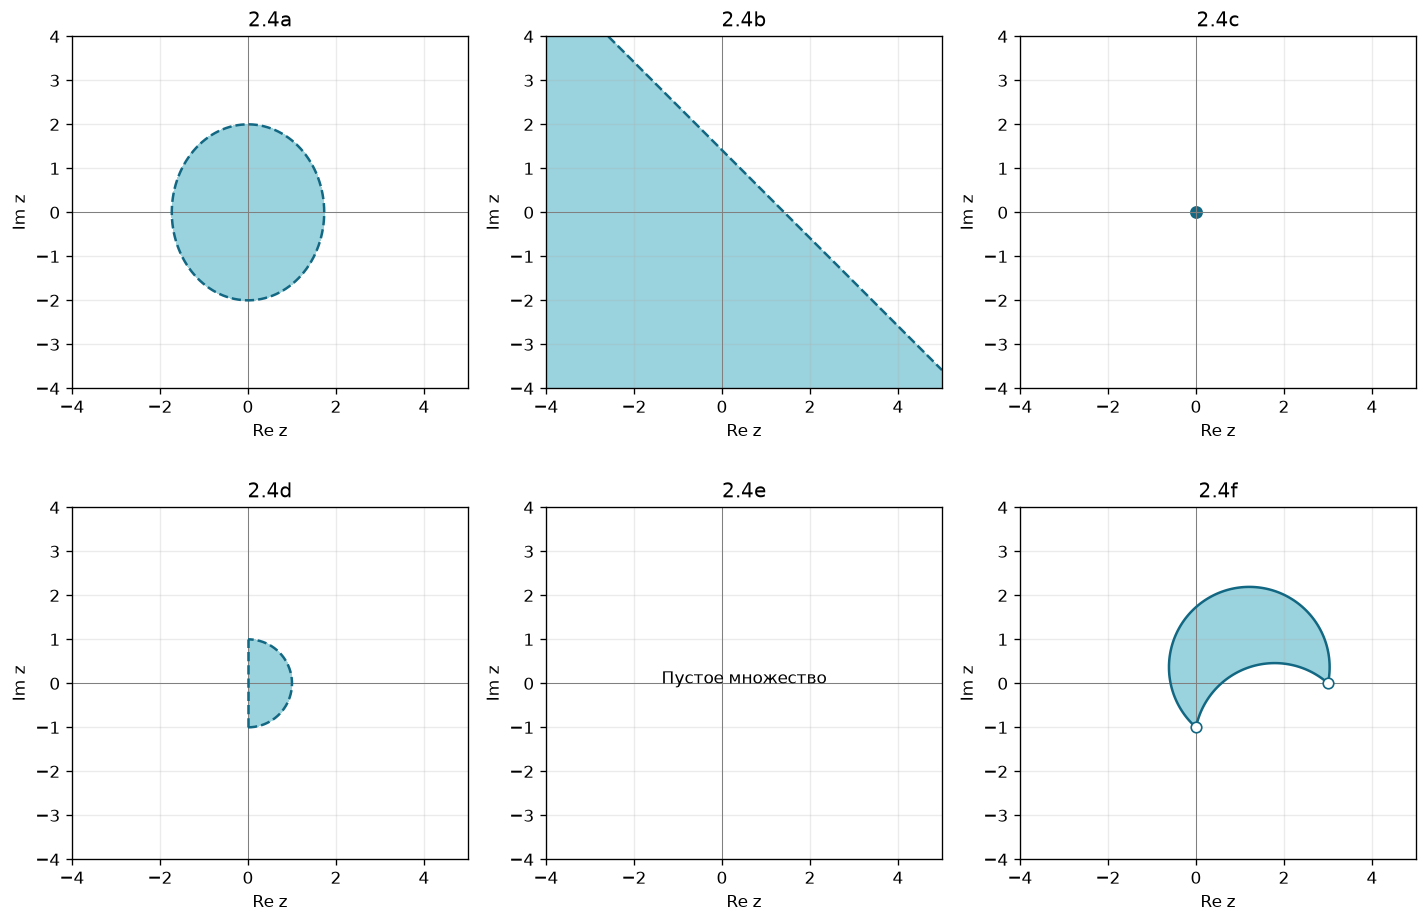

Геометрическое описание 2.4f проверено на 10000 точках.


In [5]:
xv = np.linspace(-4,5,1000); yv = np.linspace(-4,4,900)
X,Y = np.meshgrid(xv,yv)
U = 3*X-X**2-Y**2-Y; V = X-3*Y-3
masks = [X**2/3+Y**2/4<1, X+Y<np.sqrt(2), np.zeros_like(X,dtype=bool),
         (X>0)&(X**2+Y**2<1), np.zeros_like(X,dtype=bool), V<=-np.sqrt(3)*abs(U)]
fig, axes=plt.subplots(2,3,figsize=(12,8))
for ax,label,mask in zip(axes.flat,'abcdef',masks):
    ax.contourf(X,Y,mask.astype(int),levels=[.5,1.5],colors=['#88cbd7'],alpha=.85)
    complex_axes(ax,'2.4'+label)
    ax.set(xlim=(-4,5),ylim=(-4,4))
t=np.linspace(0,2*np.pi,500)
axes.flat[0].plot(np.sqrt(3)*np.cos(t),2*np.sin(t),'--',color='#126782')
axes.flat[1].plot(xv,np.sqrt(2)-xv,'--',color='#126782')
axes.flat[2].scatter([0],[0],color='#126782',s=45)
t=np.linspace(-np.pi/2,np.pi/2,300)
axes.flat[3].plot(np.cos(t),np.sin(t),'--',color='#126782')
axes.flat[3].plot([0,0],[-1,1],'--',color='#126782')
axes.flat[4].text(.5,.5,'Пустое множество',ha='center',transform=axes.flat[4].transAxes)
axes.flat[5].contour(X,Y,V+np.sqrt(3)*abs(U),levels=[0],colors=['#126782'])
axes.flat[5].scatter([3,0],[0,-1],facecolors='white',edgecolors='#126782',s=40,zorder=5)
plt.tight_layout(); save_show('2_4.png')
# Проверяем алгебраическое описание области f на случайных точках.
rng=np.random.default_rng(42); z=rng.uniform(-4,5,10000)+1j*rng.uniform(-4,4,10000)
arg=np.angle((3-z)/(z+1j))
u=3*z.real-z.real**2-z.imag**2-z.imag; v=z.real-3*z.imag-3
assert np.array_equal((arg>=-2*np.pi/3)&(arg<=-np.pi/3),v<=-np.sqrt(3)*abs(u))
print('Геометрическое описание 2.4f проверено на 10000 точках.')

## 2.5*. Центр и радиус окружности
В условии перед z стоит сопряжённое B, а второе слагаемое содержит B и сопряжённое z:
$$A|z|^2+\overline{B}z+B\overline{z}+C=0,\qquad A>0.$$
Делим на A и дополняем до квадрата:
$$\left|z+\frac{B}{A}\right|^2=\frac{|B|^2-AC}{A^2}.$$
По условию правая часть положительна. Поэтому это окружность с центром и радиусом:
$$z_0=-\frac{B}{A},\qquad R=\frac{\sqrt{|B|^2-AC}}{A}.$$
Это также доказывает утверждение для любого комплексного B.

In [6]:
A,C,b,d,x,y=sp.symbols('A C b d x y',real=True)
original=A*(x*x+y*y)+2*b*x+2*d*y+C
completed=A*((x+b/A)**2+(y+d/A)**2)-(b*b+d*d-A*C)/A
assert sp.simplify(original-completed)==0
print('Тождество дополнения до квадрата проверено символически.')

Тождество дополнения до квадрата проверено символически.


## 2.6. Одиннадцать корней многочлена
$$p(x)=x^{11}+x^{10}+x^8-2x^7-x^5+x^4+2x^2+2x+2.$$
Корни вычислены численно с рабочей точностью 40 десятичных знаков. Ниже они округлены до 12 знаков после запятой:
1. -1.776769024921 +0.000000000000i

2. -0.707434455212 -0.464374725865i

3. -0.707434455212 +0.464374725865i

4. -0.450037112743 -0.803923144248i

5. -0.450037112743 +0.803923144248i

6. -0.012500180565 -1.182699081746i

7. -0.012500180565 +1.182699081746i

8. 0.477754523623 -0.901075230538i

9. 0.477754523623 +0.901075230538i

10. 1.080601737358 -0.323893118840i

11. 1.080601737358 +0.323893118840i

Искомые величины (сумма модулей вычисляется по неокруглённым корням):
$$\sum_{k=1}^{11}|z_k|=11.973384469712.$$
$$\max_k\operatorname{Re}z_k=1.080601737358.$$
Корни проверены подстановкой и формулами Виета; подробные численные остатки выведены в ноутбуке.

In [7]:
x=sp.symbols('x')
p=x**11+x**10+x**8-2*x**7-x**5+x**4+2*x**2+2*x+2
roots_mp=sp.nroots(p,n=40,maxsteps=200)
roots26=np.array(sorted([complex(r) for r in roots_mp],key=lambda z:(z.real,z.imag)))
for k,z in enumerate(roots26,1): print(k,f'{z.real:.12f}{z.imag:+.12f}i')
print('Сумма модулей:', sum(abs(z) for z in roots26))
print('Максимальная действительная часть:',max(z.real for z in roots26))
residual=max(abs(complex(p.subs(x,z).evalf())) for z in roots26)
print('Максимальный остаток после перевода в complex128:',residual)
assert residual < 1e-10
assert abs(sum(roots26)+1)<1e-12
assert abs(np.prod(roots26)+2)<1e-12
assert np.max(abs(np.poly(roots26)-np.array([1,1,0,1,-2,0,-1,1,0,2,2,2])))<1e-10
print('Все коэффициенты восстановлены по корням; проверка пройдена.')

1 -1.776769024921+0.000000000000i
2 -0.707434455212-0.464374725865i
3 -0.707434455212+0.464374725865i
4 -0.450037112743-0.803923144248i
5 -0.450037112743+0.803923144248i
6 -0.012500180565-1.182699081746i
7 -0.012500180565+1.182699081746i
8 0.477754523623-0.901075230538i
9 0.477754523623+0.901075230538i
10 1.080601737358-0.323893118840i
11 1.080601737358+0.323893118840i
Сумма модулей: 11.97338446971212
Максимальная действительная часть: 1.0806017373578454
Максимальный остаток после перевода в complex128: 2.5757174171303632e-14
Все коэффициенты восстановлены по корням; проверка пройдена.


## 2.7. Обобщённые биномиальные коэффициенты
### a), b) Значение и аргумент
$$C_z^w=\frac{\Gamma(z+1)}{\Gamma(w+1)\Gamma(z-w+1)}.$$
При z = 1 + i и w = 1 минус i получаем:
$$C_{1+i}^{1-i}=\frac{\Gamma(2+i)}{\Gamma(2-i)\Gamma(1+2i)}.$$
Численный результат:
$$C_{1+i}^{1-i}\approx4.3674491406+4.8516297652i.$$
$$\operatorname{Arg}C_{1+i}^{1-i}\approx0.8378693696\;\mathrm{rad}\approx48.0063786585^\circ.$$
### c) Линии уровня аргумента
В показателе коэффициента в оригинале стоит 1/z. Значит, строится аргумент следующей функции:
$$F(z)=C_z^{1/z}=\frac{\Gamma(z+1)}{\Gamma(1+1/z)\Gamma(z+1-1/z)}.$$
Используем логарифмы гамма-функций, чтобы избежать переполнения. Мнимая часть их разности приводится к главной ветви аргумента. Точка z = 0 исключается; нули, полюсы и разрывы главного аргумента не соединяются контурными линиями. Изображение строится в квадрате от минус 2 до 2 по обеим координатам с шагом сетки примерно 0.005; очень близко к нулю структура требует отдельного увеличения.

C = (4.367449140640138967228260738593492149297 + 4.851629765157811540851967673682118273424j)
Arg = 0.837869369550041912072550919661 rad; 48.0063786585044915551614869993 град.


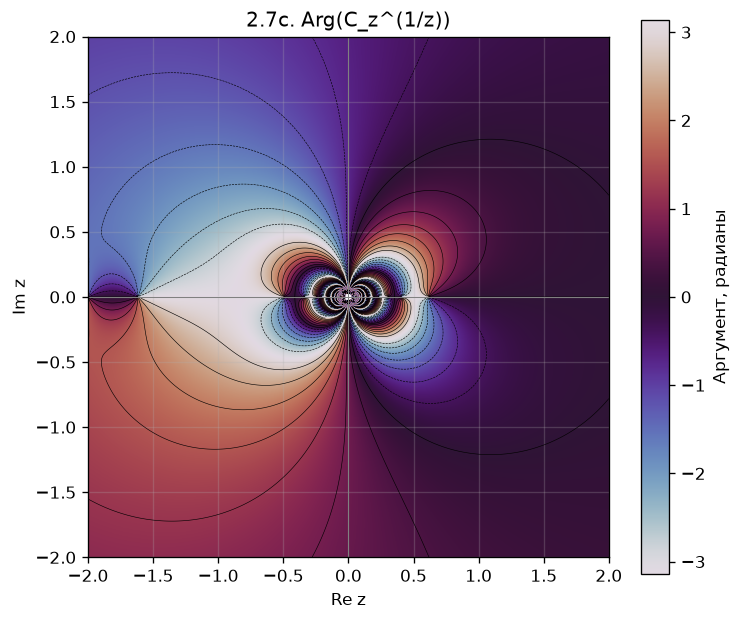

In [8]:
z=mp.mpc(1,1); w=mp.mpc(1,-1)
bcoef=mp.gamma(z+1)/(mp.gamma(w+1)*mp.gamma(z-w+1))
arg=mp.arg(bcoef)
print('C =',mp.nstr(bcoef,40))
print('Arg =',mp.nstr(arg,30),'rad;',mp.nstr(arg*180/mp.pi,30),'град.')
xx=np.linspace(-2,2,801); yy=np.linspace(-2,2,801)
XX,YY=np.meshgrid(xx,yy); ZZ=XX+1j*YY
with np.errstate(all='ignore'):
    L=loggamma(ZZ+1)-loggamma(1+1/ZZ)-loggamma(ZZ+1-1/ZZ)
    phase=np.angle(np.exp(1j*L.imag))
mask=(abs(ZZ)<.025)|(~np.isfinite(L))
# Исключаем клетки, пересекающие разрыв главного аргумента.
cut=np.zeros_like(mask)
dh=abs(np.diff(phase,axis=1))>np.pi
dv=abs(np.diff(phase,axis=0))>np.pi
cut[:,:-1]|=dh;cut[:,1:]|=dh;cut[:-1,:]|=dv;cut[1:,:]|=dv
phase_masked=np.ma.array(phase,mask=mask|cut)
fig,ax=plt.subplots(figsize=(7,6))
im=ax.imshow(np.ma.array(phase,mask=mask),extent=(-2,2,-2,2),origin='lower',cmap='twilight',vmin=-np.pi,vmax=np.pi)
ax.contour(XX,YY,phase_masked,levels=np.linspace(-np.pi,np.pi,17)[1:-1],colors='black',linewidths=.35)
complex_axes(ax,'2.7c. Arg(C_z^(1/z))')
fig.colorbar(im,ax=ax,label='Аргумент, радианы')
save_show('2_7.png')

## 2.8. Определитель с корнем из единицы
Из корней 14-й степени с положительной мнимой частью наибольшую действительную часть имеет:
$$\lambda=e^{i\pi/7}=\cos\frac{\pi}{7}+i\sin\frac{\pi}{7}.$$
$$\det(A+\lambda I)=(7+\lambda)(2+\lambda)-30=\lambda^2+9\lambda-16.$$
Следовательно:
$$\operatorname{Re}\det=\cos\frac{2\pi}{7}+9\cos\frac{\pi}{7}-16,$$
$$\operatorname{Im}\det=\sin\frac{2\pi}{7}+9\sin\frac{\pi}{7}.$$
Численные значения приведены в выводе программы и в итоговых ответах.

In [9]:
lam=mp.exp(mp.j*mp.pi/7)
det=lam**2+9*lam-16
print('lambda =',mp.nstr(lam,25))
print('Re det =',mp.nstr(det.real,30))
print('Im det =',mp.nstr(det.imag,30))
mat=np.array([[7,5],[6,2]],dtype=complex)+complex(lam)*np.eye(2)
assert abs(np.linalg.det(mat)-complex(det))<1e-12

lambda = (0.9009688679024191262361023 + 0.4338837391175581204757683j)
Re det = -7.26779038701949433335007424043
Im det = 4.68678513452605289299035952231


## 2.9*. Множества Жюлиа
Множество Жюлиа описывает точки неустойчивой динамики при многократном применении комплексной функции. Для полинома оно является границей заполненного множества Жюлиа, то есть множества точек с ограниченной орбитой.
### Квадратичные функции
Для обеих заданных констант реализован метод времени ухода:
$$z_{n+1}=z_n^2+c,\qquad c=-0.1+0.65i\quad\mathrm{or}\quad c=0.28+0.009i.$$
Радиус ухода равен 2, так как модули обеих констант меньше 2. Если модуль очередного значения больше 2, орбита уходит к бесконечности. Чёрные точки на рисунке не ушли за 700 итераций; конечное число итераций даёт приближение заполненного множества, его граница приближает само множество Жюлиа.
### Рациональные функции
$$f_1(z)=\frac{iz^5-1}{z^5-i},\qquad f_2(z)=\frac{z^2+i}{1-z^2}.$$
Для рациональных функций большой модуль сам по себе не означает ухода к бесконечности: следующая итерация может вернуться в конечную область. Поэтому применён метод случайных обратных итераций. Из уравнения f(z) = w находим все прообразы:
$$z^5=\frac{iw-1}{w-i}\quad\mathrm{for}\ f_1,\qquad z^2=\frac{w-i}{w+1}\quad\mathrm{for}\ f_2.$$
На каждом шаге случайно выбирается одна из пяти или двух ветвей корня. После 1000 начальных шагов сохраняются 220000 точек. Начальное значение и генератор случайных чисел фиксированы; результат воспроизводим. Это численная визуализация, а не доказательство точности каждой границы. Код обеих программ находится в ноутбуке.

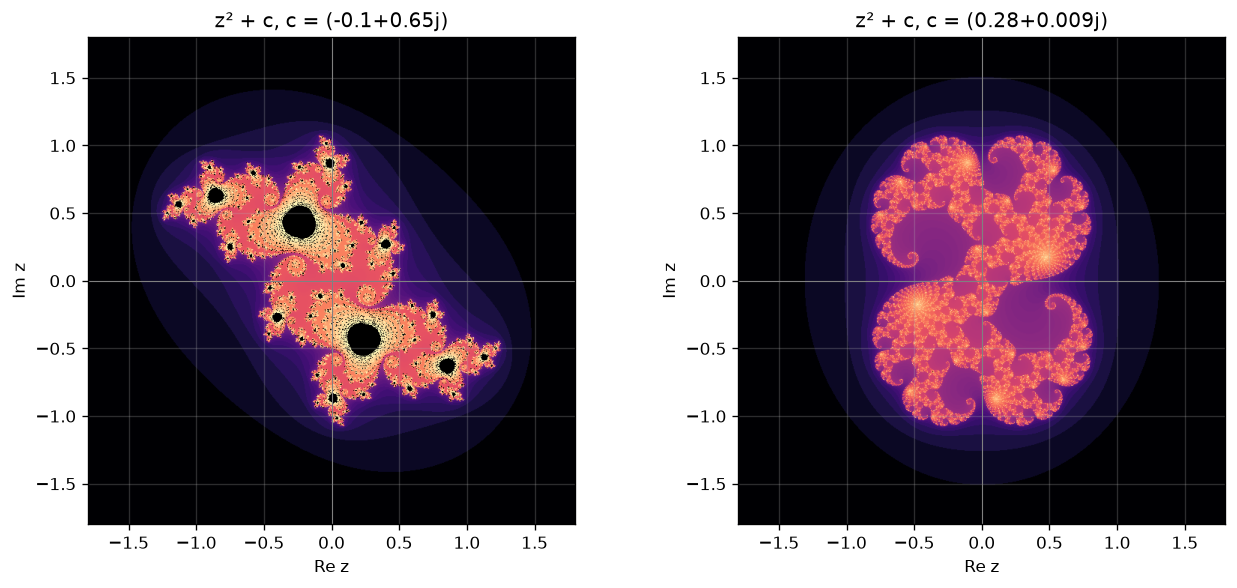

Рациональная функция 1 : конечных точек 220000


Рациональная функция 2 : конечных точек 220000


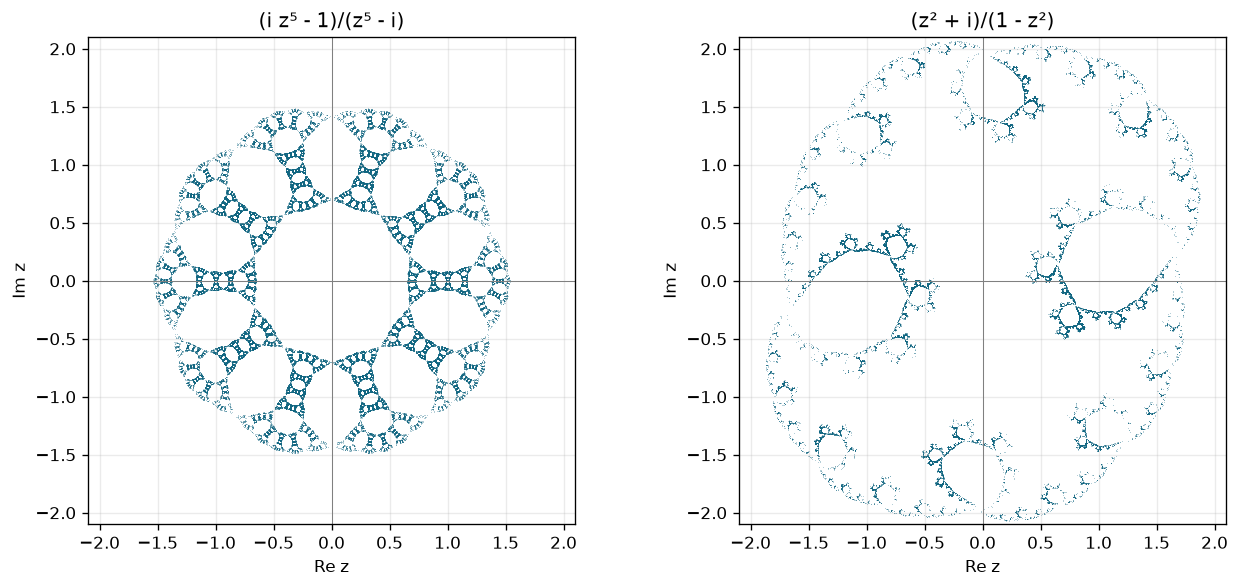

Все ветви обратных отображений проверены.


In [10]:
def escape_image(c,n=650,iterations=700):
    axis=np.linspace(-1.8,1.8,n)
    Z=axis[None,:]+1j*axis[:,None]
    active=np.ones(Z.shape,dtype=bool)
    time=np.full(Z.shape,iterations,dtype=float)
    for k in range(iterations):
        Z[active]=Z[active]**2+c
        escaped=active & (abs(Z)>2)
        time[escaped]=k+1; active[escaped]=False
        if not active.any(): break
    return np.ma.masked_where(active,np.log1p(time))
fig,axes=plt.subplots(1,2,figsize=(11,5))
cmap=plt.get_cmap('magma').copy();cmap.set_bad('black')
for ax,c in zip(axes,[-.1+.65j,.28+.009j]):
    ax.imshow(escape_image(c),extent=(-1.8,1.8,-1.8,1.8),origin='lower',cmap=cmap)
    complex_axes(ax,f'z² + c, c = {c}')
plt.tight_layout();save_show('2_9_quadratic.png')

def inverse_julia(which,count=220000,burn=1000,seed=2026):
    rng=np.random.default_rng(seed); w=.31+.57j
    degree=5 if which==1 else 2
    points=np.empty(count,dtype=complex)
    for k in range(count+burn):
        if which==1:
            q=(1j*w-1)/(w-1j)
        else:
            q=(w-1j)/(w+1)
        branch=rng.integers(degree)
        w=abs(q)**(1/degree)*np.exp(1j*(np.angle(q)+2*np.pi*branch)/degree)
        if k>=burn: points[k-burn]=w
    return points
fig,axes=plt.subplots(1,2,figsize=(11,5))
for ax,k,title in zip(axes,[1,2],['(i z⁵ - 1)/(z⁵ - i)','(z² + i)/(1 - z²)']):
    pts=inverse_julia(k)
    ax.scatter(pts.real,pts.imag,s=.08,c='#126782',rasterized=True,linewidths=0)
    ax.set(xlim=(-2.1,2.1),ylim=(-2.1,2.1))
    complex_axes(ax,title)
    print('Рациональная функция',k,': конечных точек',np.isfinite(pts).sum())
plt.tight_layout();save_show('2_9_rational.png')
# Проверка формул обратных отображений для всех ветвей.
for w in [.31+.57j, 2+.3j, -.4-2j]:
    for k,n in [(1,5),(2,2)]:
        q=(1j*w-1)/(w-1j) if k==1 else (w-1j)/(w+1)
        zs=all_roots(q,n)
        fw=(1j*zs**5-1)/(zs**5-1j) if k==1 else (zs**2+1j)/(1-zs**2)
        assert max(abs(fw-w))<1e-10
print('Все ветви обратных отображений проверены.')

## 2.10*. Кривые на сфере Римана
Используем единичную сферу. Обратная стереографическая проекция из северного полюса переводит комплексное число z = x + iy в точку:
$$X=\frac{2x}{1+x^2+y^2},\quad Y=\frac{2y}{1+x^2+y^2},\quad Z=\frac{x^2+y^2-1}{1+x^2+y^2}.$$
Нуль переходит в южный полюс, бесконечность соответствует северному. Подстановка показывает, что сумма квадратов трёх координат равна 1.
В условии конкретные коэффициенты кривых не заданы, поэтому выбраны следующие примеры:
Прямая: z(t) = t + 0.5i; окружность: z(t) = 0.4 + 1.2 exp(it); парабола: z(t) = t + it²; гипербола: z(t) = ±cosh(t) + i sinh(t). У гиперболы построены обе ветви.
На графиках прямая, парабола и гипербола приближаются к северному полюсу при неограниченном параметре. Сам полюс не соответствует конечной точке этих кривых.
### Второй пункт 2.10*: логарифмическая спираль
$$r=ae^{b\varphi},\qquad z(\varphi)=ae^{b\varphi}e^{i\varphi}.$$
Коэффициенты в условии не заданы. Выбраны a = 0.5 и b = 0.18; их можно изменить в коде. Для ненулевого положительного b при стремлении параметра к минус бесконечности образ приближается к южному полюсу, а при стремлении к плюс бесконечности к северному.

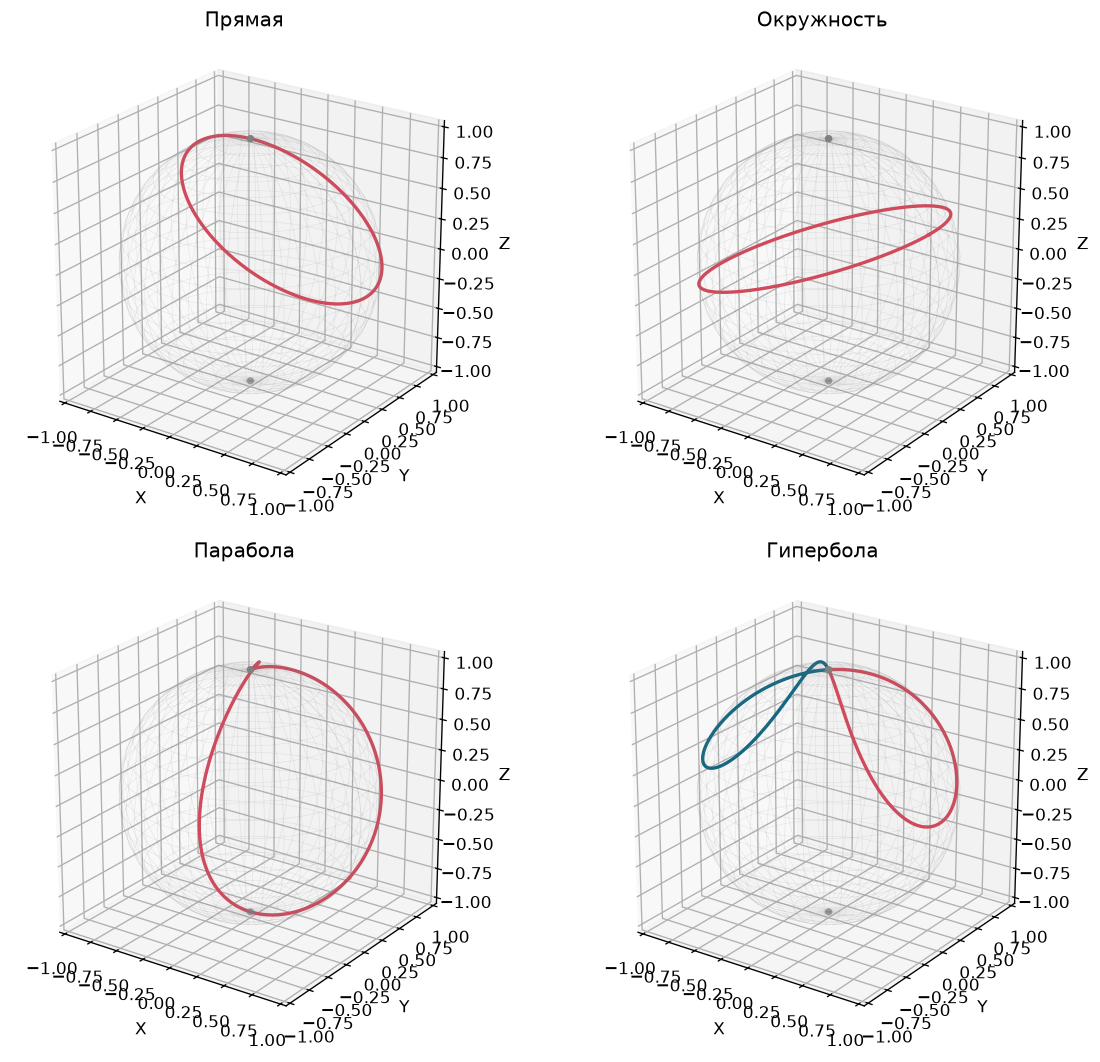

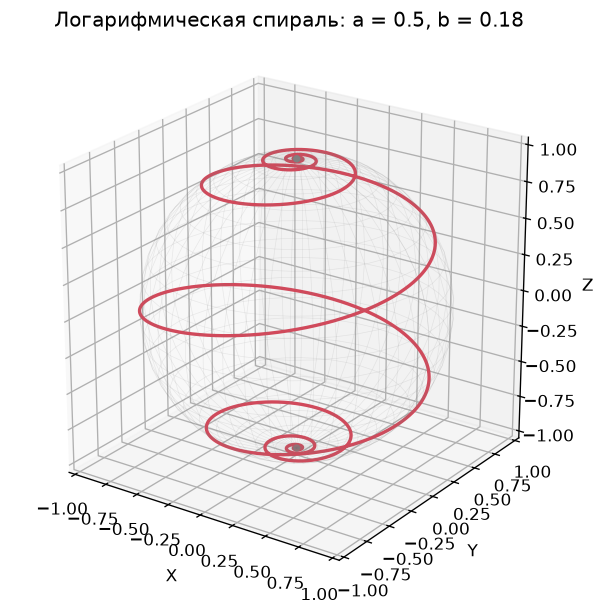

Все построенные точки лежат на единичной сфере с точностью 2e-14.


In [11]:
def sphere_map(z):
    z=np.asarray(z,dtype=complex); r2=abs(z)**2
    return 2*z.real/(1+r2),2*z.imag/(1+r2),(r2-1)/(1+r2)
def sphere_base(ax,title):
    u=np.linspace(0,2*np.pi,45);v=np.linspace(0,np.pi,24)
    ax.plot_wireframe(np.outer(np.cos(u),np.sin(v)),np.outer(np.sin(u),np.sin(v)),
                      np.outer(np.ones_like(u),np.cos(v)),color='gray',alpha=.14,lw=.4)
    ax.scatter([0,0],[0,0],[-1,1],color='gray',s=12)
    ax.set(xlim=(-1.05,1.05),ylim=(-1.05,1.05),zlim=(-1.05,1.05),
           xlabel='X',ylabel='Y',zlabel='Z',title=title)
    ax.set_box_aspect((1,1,1));ax.view_init(23,-55)
def sphere_curve(ax,z,color='#d1495b'):
    coords=sphere_map(z)
    assert np.max(abs(sum(c*c for c in coords)-1))<2e-14
    ax.plot(*coords,color=color,lw=2)
t=np.concatenate([-np.geomspace(1e4,.02,1500),np.linspace(-.02,.02,50),np.geomspace(.02,1e4,1500)])
theta=np.linspace(0,2*np.pi,2000);th=np.linspace(-12,12,4000)
fig=plt.figure(figsize=(10,9))
for j,title in enumerate(['Прямая','Окружность','Парабола','Гипербола'],1):
    ax=fig.add_subplot(2,2,j,projection='3d');sphere_base(ax,title)
    if j==1: sphere_curve(ax,t+.5j)
    elif j==2: sphere_curve(ax,.4+1.2*np.exp(1j*theta))
    elif j==3: sphere_curve(ax,t+1j*t*t)
    else:
        sphere_curve(ax,np.cosh(th)+1j*np.sinh(th))
        sphere_curve(ax,-np.cosh(th)+1j*np.sinh(th),'#126782')
plt.tight_layout();save_show('2_10_curves.png')
a,b=.5,.18
phi=np.linspace(-16*np.pi,16*np.pi,12000)
spiral=a*np.exp(b*phi)*np.exp(1j*phi)
fig=plt.figure(figsize=(7,6));ax=fig.add_subplot(projection='3d')
sphere_base(ax,'Логарифмическая спираль: a = 0.5, b = 0.18')
sphere_curve(ax,spiral)
save_show('2_10_spiral.png')
print('Все построенные точки лежат на единичной сфере с точностью 2e-14.')

## Итоговые ответы и источники
2.1: a) 10 минус 11i; b) 2; c) минус 64. Тригонометрические и показательные формы приведены в решении.
2.2 и 2.3: формулы всех корней и рисунки приведены выше.
2.4: a) внутренность эллипса; b) открытая полуплоскость; c) нуль; d) правая половина открытого единичного круга; e) пустое множество; f) область, заданная неравенством для U и V, с исключёнными точками минус i и 3.
2.5: центр минус B/A, радиус равен корню из разности квадрата модуля B и AC, делённому на A.
2.6: сумма модулей 11.973384469712; максимальная действительная часть 1.080601737358.
2.7: значение 4.36745 + 4.85163i; аргумент примерно 0.837869 радиана.
2.8: действительная часть -7.267790387019494; мнимая часть 4.686785134526053.
2.9 и оба пункта 2.10: программы выполнены; графики сохранены в ноутбуке и приложены к отчёту.
Источник условий: приложенный PDF «Практические занятия Листок 2.pdf», П. Е. Рябов.
Теория множеств Жюлиа и обратных итераций: https://en.wikipedia.org/wiki/Julia_set
Вычисление логарифма гамма-функции: https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.loggamma.html